# Control rápido por eventos: método en la práctica

**Nivel:** 2  
**Requisitos previos:** Control rápido por eventos nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** Cuando M01 y M02 ejecutan C01 con la misma semilla, ¿coinciden sus resultados verificados independientemente?


## Objetivos

Para el nivel 2 de control de eventos con guardas en C01, Explica cómo una observación de evento se convierte en una elección acotada. Para el nivel 2 de control de eventos con guardas en C01, La distinción central está entre ordenar un candidato registrado y otorgarle autoridad: Para el nivel 2 de control de eventos con guardas en C01, el entorno admite solo la acción cuyos herramienta, argumentos y revisión del recurso satisfacen el contrato.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 2 de control de eventos con guardas en C01, El notebook lee artefactos comprometidos del producto. Para el nivel 2 de control de eventos con guardas en C01, Propietario: Para el nivel 2 de control de eventos con guardas en C01, Neuraxis. Para el nivel 2 de control de eventos con guardas en C01, Repositorio: Para el nivel 2 de control de eventos con guardas en C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 2 de control de eventos con guardas en C01, Apache-2.0. Para el nivel 2 de control de eventos con guardas en C01, El JSON es un artefacto experimental propio y congelado; Para el nivel 2 de control de eventos con guardas en C01, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 2 de control de eventos con guardas en C01, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 2 de control de eventos con guardas en C01, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 2 de control de eventos con guardas en C01, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 2 de control de eventos con guardas en C01, El manifiesto de publicación verifica los hashes. Para el nivel 2 de control de eventos con guardas en C01, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 2 de control de eventos con guardas en C01, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M02-C01-nominal-40000.json`


## Método

Para el nivel 2 de control de eventos con guardas en C01, El conjunto de candidatos es el espacio de acciones de esta decisión, no de las siguientes. Para el nivel 2 de control de eventos con guardas en C01, Una regla o puntuación no puede agregar una capacidad ausente, omitir una revisión obsoleta ni reinterpretar texto de archivo no confiable como instrucción. Para el nivel 2 de control de eventos con guardas en C01, La FSM y el árbol de comportamiento son referencias implementadas por separado; Para el nivel 2 de control de eventos con guardas en C01, coincidir en una tarea breve no los convierte en el mismo algoritmo. Para el nivel 2 de control de eventos con guardas en C01, La traza sirve porque expone la observación exacta, los candidatos admisibles, la primera acción y el resultado del oráculo. Para el nivel 2 de control de eventos con guardas en C01, Su forma de un paso también limita lo que enseña: Para el nivel 2 de control de eventos con guardas en C01, no prueba recuperación tras eventos tardíos, carreras de cancelación, herramientas nuevas ni cambios de distribución. Para el nivel 2 de control de eventos con guardas en C01, Esos mecanismos requieren casos y resultados independientes. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, La máscara de admisibilidad define las acciones que el entorno puede ejecutar con seguridad. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, la puntuación solo ordena ese conjunto y no crea capacidades ni invalida una revisión obsoleta del recurso. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, El controlador de estados finitos ofrece una referencia inferior útil porque sus reglas son inspeccionables y deterministas. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, un árbol de comportamiento expresa la tarea con guardas y alternativas explícitas. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, Una prueba de estrés relevante cambia el tiempo del evento o la disponibilidad de candidatos sin alterar el contrato, y verifica la poscondición en vez de comparar solo la primera acción. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, Lee la traza como observación, conjunto admisible, acción elegida y resultado de un oráculo independiente. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, unir esos campos en una sola etiqueta de éxito oculta el origen de la autoridad. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, La coincidencia en un caso solo demuestra consistencia local. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, la robustez requiere semillas y perturbaciones independientes que revelen estados obsoletos, candidatos ausentes y efectos no autorizados. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, En este nivel, informa si cada acción elegida permanece dentro del contrato declarado de herramienta y recurso. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, distingue una negativa segura de un fallo de tarea en la tabla. Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, para control de eventos con guardas en C01, Una extensión útil cambia un orden de eventos por vez, conserva el oráculo del caso y registra qué transición produjo la divergencia para reproducir la respuesta.


### control de eventos con guardas · nivel 2 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M02"]
trace_methods = ["M01", "M02"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 2


### control de eventos con guardas · nivel 2 — Ejecuta las políticas publicadas y compara la corrida


### control de eventos con guardas · nivel 2 — Compara la secuencia completa y no solo la primera acción


### control de eventos con guardas · L2 — Construir la primera política ejecutable

En el nivel 2, construye M01 para control de eventos con guardas con la fábrica pública y conserva su contrato de observación antes de muestrear C01.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### control de eventos con guardas · L2 — Ejecutar el método principal en el caso indicado

En el nivel 2 de control de eventos con guardas, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### control de eventos con guardas · L2 — Construir una política de comparación independiente

Para el nivel 2 de control de eventos con guardas, crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### control de eventos con guardas · L2 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 2 ejecuta M02 en el mismo C01, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### control de eventos con guardas · L2 — Agregar los dos episodios ejecutados

En el nivel 2, el agregador resume dos episodios ejecutados de control de eventos con guardas, and las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### control de eventos con guardas · L2 — Resultados de políticas nuevas

Para el nivel 2 de control de eventos con guardas en C01, El gráfico siguiente se calcula con los resultados de episodios de control de eventos con guardas recién ejecutados en C01, no se copia de un artefacto congelado.


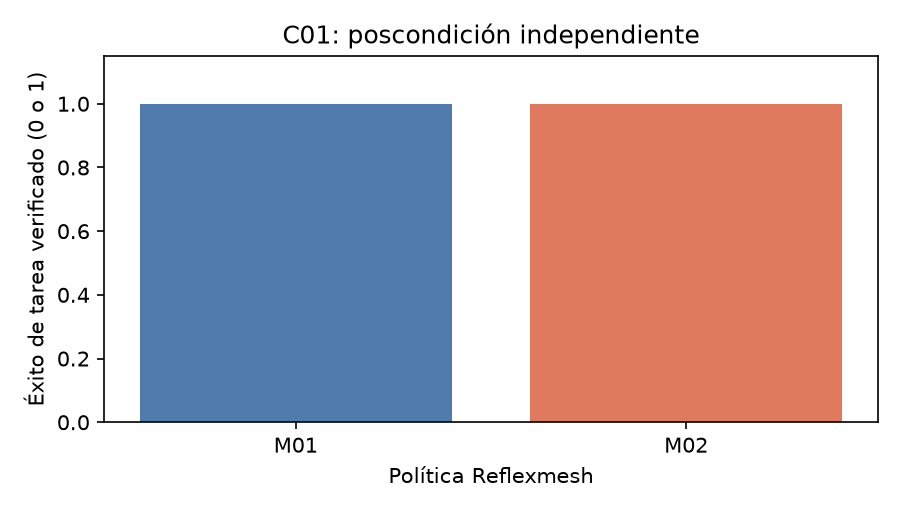

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 2 de control de eventos con guardas en C01, Para control de eventos con guardas, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C01; Para el nivel 2 de control de eventos con guardas en C01, éxito vale 1 y falla 0. Para el nivel 2 de control de eventos con guardas en C01, Lee el caso y la semilla antes de compararlas. Para el nivel 2 de control de eventos con guardas en C01, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


### control de eventos con guardas · L2 — Tiempo registrado del controlador

En el nivel 2, la figura de tiempos de control de eventos con guardas usa registros congelados y verificados por hash para M01 y M02 en C01, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 2 para control de eventos con guardas describe el entorno registrado bajo su caso, variante y semilla declarados.

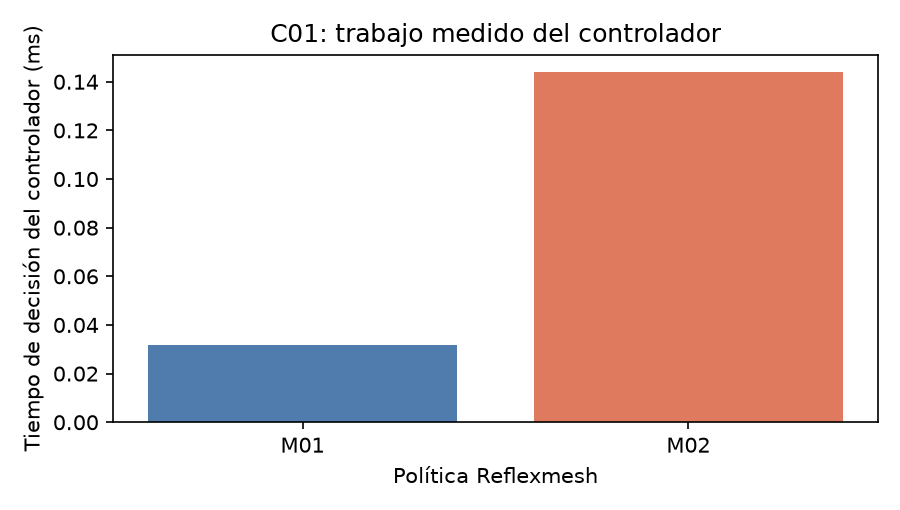

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: trabajo medido del controlador")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 2 para control de eventos con guardas lee registros canónicos de M01/M02 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de control de eventos con guardas, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de control de eventos con guardas ejecuta 2 episodios nuevos de M01 y M02 bajo condiciones C01 idénticas; conserva a la vista las familias y semillas de control de eventos con guardas, porque la matriz contiene tareas diseñadas y no una muestra poblacional.

Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Esta repetición con el paquete comprueba una decisión protegida exacta sobre la misma observación congelada. Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, No demuestra transferencia general, un mecanismo biológico ni superioridad frente a un sistema desplegado y emparejado.

Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Este paso de autoría no compromete salidas generadas; Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, Para el nivel 2 de control de eventos con guardas en C01, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 2 de control de eventos con guardas en C01, En el nivel 2, control de eventos con guardas usa C01 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 2 de control de eventos con guardas en C01, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [LEE](https://doi.org/10.1016/j.neuron.2013.11.028)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
